### <font color = "gold"> Import les librairies requises

In [ ]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [ ]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [ ]:
# Importer les données
df = pd.read_csv('/content/wheat_seeds_dataset.csv')

**Nous avons ici des données de graines de blé. Chaque graine de blé est caractérisée par 7 variables morphologiques (issues de l'étude morphologique de chaque graine).**

In [ ]:
# Afficher les données
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [ ]:
# Dimension des données
df.shape

(199, 7)

In [ ]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [ ]:
# Décrire les données
df.describe().T


,count,mean,std,min,25%,50%,75%,max
area A,199.0,14.918744,2.919976,10.5900,12.3300,14.4300,17.4550,21.1800
perimeter,199.0,14.595829,1.310445,12.4100,13.4700,14.3700,15.8050,17.2500
compactness,199.0,0.870811,0.023320,0.8081,0.8571,0.8734,0.8868,0.9183
length of kernel,199.0,5.643151,0.443593,4.8990,5.2670,5.5410,6.0020,6.6750
width of kernel,199.0,3.265533,0.378322,2.6300,2.9545,3.2450,3.5645,4.0330
asymmetry coefficient,199.0,3.699217,1.471102,0.7651,2.5700,3.6310,4.7990,8.3150
length of kernel groove,199.0,5.420653,0.492718,4.5190,5.0460,5.2280,5.8790,6.5500


In [ ]:
# Renommer les index de manière optimisée
df.rename(index=lambda i: f"Graine{i+1}", inplace=True)

# Afficher un aperçu pour vérifier les nouveaux index
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Graine1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Graine2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Graine3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Graine4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Graine5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [ ]:
# Matrice des données
x = df.values
x[ :5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

#### <font color = "gold"> Appliquer une ACP

In [ ]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)

# Matrice des 2 composantes
features_pca = pca.fit_transform(x)
# Dataframe
df_pca = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])

In [ ]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(99.3)

### <font color = "gold"> Kmeans

In [ ]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

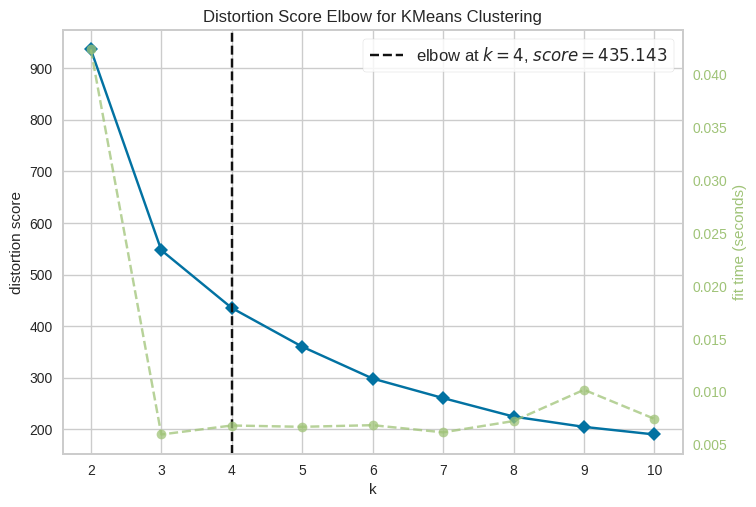

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [ ]:
# Initier le modèle
kmeans_model = KMeans(n_clusters=4, init= 'random', max_iter= 500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=4)

#### <font color = "bisque"> Prédiction la partition

In [ ]:
# Prediction de la partition(l'ensemble des classes) de X
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 2, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 0, 0, 0, 0, 2,
       1, 1, 1, 3, 1, 1, 1, 3, 3, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 1, 3, 3, 3, 3, 1, 3, 3, 3, 3, 3, 1, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 1, 3, 1, 3, 3, 3, 3, 1, 3, 3, 1, 1, 1, 1, 1,
       1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2,
       2], dtype=int32)

In [ ]:
# Nombre d'observations dans chaque class
val = pd.Series(kmeans_partition).value_counts()
val

,count
2,69
0,54
3,47
1,29


In [ ]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x = val.index, y = val.values ,color = val.index.astype(str))
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

In [ ]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PC1', y = 'PC2', color = kmeans_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [ ]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x, kmeans_partition)
print(f'silhouette score :{sil_kmeans}')

silhouette score :0.41822883561631463


In [ ]:
kmeans_partition == 0

array([ True,  True,  True,  True,  True,  True,  True, False, False,
       False,  True,  True,  True,  True,  True, False,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True,  True,  True, False, False,
        True, False,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True, False, False, False,  True,  True,
        True,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [ ]:
# Les graines de chaque classes
clusters_names = []
for i in range(4):
  clusters_names.append(list(df.index[kmeans_partition == i]))

In [ ]:
# Afficher les graines de la classe 0
print(clusters_names[3])

['Graine70', 'Graine74', 'Graine75', 'Graine78', 'Graine79', 'Graine80', 'Graine81', 'Graine82', 'Graine83', 'Graine84', 'Graine85', 'Graine86', 'Graine87', 'Graine88', 'Graine89', 'Graine90', 'Graine91', 'Graine93', 'Graine94', 'Graine95', 'Graine96', 'Graine98', 'Graine99', 'Graine100', 'Graine101', 'Graine102', 'Graine104', 'Graine105', 'Graine106', 'Graine107', 'Graine108', 'Graine109', 'Graine110', 'Graine111', 'Graine112', 'Graine113', 'Graine114', 'Graine115', 'Graine116', 'Graine117', 'Graine119', 'Graine121', 'Graine122', 'Graine123', 'Graine124', 'Graine126', 'Graine127']


### <font color = "gold"> CAH

In [ ]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Nombre de classes retenu pour la CAH (comme Kmeans ; à ajuster d'après le dendrogramme)
k_cah = 4

# Matrice des liaisons (liaison moyenne, comme dans le notebook Customer du prof)
Z = linkage(x, method='average')

# Visualiser le dendrogramme (tronqué aux 30 derniers regroupements pour rester lisible)
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)

# Ligne rouge : coupure donnant k_cah classes
seuil = (Z[-(k_cah - 1), 2] + Z[-k_cah, 2]) / 2
plt.axhline(y=seuil, color='red', linestyle='--')
plt.title('Dendrogramme (liaison moyenne)')
plt.xlabel("Individus (ou nombre d'individus regroupés)")
plt.ylabel('Distance')
plt.show()

##### <font color = "bisque"> Choix du nombre de classes et de la méthode de liaison

In [ ]:
# Importer AgglomerativeClustering
from sklearn.cluster import AgglomerativeClustering

# Silhouette de la CAH (liaison moyenne) selon le nombre de classes
for k in range(2, 9):
    part = AgglomerativeClustering(n_clusters=k, linkage='average').fit_predict(x)
    print(f"k = {k}   silhouette = {silhouette_score(x, part):.3f}")

In [ ]:
# Comparer plusieurs méthodes de liaison pour k_cah classes
for lien in ['ward', 'average', 'complete', 'single']:
    part = AgglomerativeClustering(n_clusters=k_cah, linkage=lien).fit_predict(x)
    print(f"{lien:9s} silhouette = {silhouette_score(x, part):.3f}   effectifs = {np.bincount(part)}")

**Choix de la liaison.** On reprend la liaison **moyenne** (`average`) du notebook Customer du prof : pour k = 4, c'est elle qui donne la meilleure silhouette parmi les liaisons testées (environ 0,39, contre environ 0,35 pour Ward), avec des classes de tailles raisonnables. La liaison `single` est à écarter : elle met presque toutes les graines dans une seule classe.

#### <font color = "bisque"> Appliquer la CAH

In [ ]:
# Initier AgglomerativeClustering (liaison moyenne)
cah_model = AgglomerativeClustering(n_clusters=k_cah, linkage='average')
# Entrainer le modèle et prédire la partition
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition

In [ ]:
# Nombre d'observations dans chaque classe
val_cah = pd.Series(cah_partition).value_counts()
val_cah

In [ ]:
# Diagramme en barre du nombre d'observations dans chaque classe
fig = px.bar(x = val_cah.index, y = val_cah.values, color = val_cah.index.astype(str))
fig.show()

#### <font color = "bisque"> Visualiser les classes prédites par la CAH

In [ ]:
# Visualiser les classes suivant les deux composantes
fig = px.scatter(df_pca, x = 'PC1', y = 'PC2', color = cah_partition.astype(str))
fig.show()

In [ ]:
# Indice de silhouette de la partition de la CAH
sil_cah = silhouette_score(x, cah_partition)
print(f'silhouette score :{sil_cah}')

### <font color = "gold"> Comparaison de Kmeans et de la CAH

In [ ]:
# Diagramme en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x = Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [ ]:
# Accord entre les deux partitions (1 = identiques, 0 = accord dû au hasard)
from sklearn.metrics import adjusted_rand_score
print("Indice de Rand ajusté Kmeans / CAH :", round(adjusted_rand_score(kmeans_partition, cah_partition), 3))

# Tableau croisé des deux partitions (les numéros de classes sont arbitraires)
pd.crosstab(kmeans_partition, cah_partition, rownames=['Kmeans'], colnames=['CAH'])

In [ ]:
# Les graines de chaque classe de la CAH
cah_clusters_names = []
for i in range(k_cah):
    cah_clusters_names.append(list(df.index[cah_partition == i]))
print(cah_clusters_names[0][:20])

### <font color = "gold"> Déploiement du meilleur modèle avec Streamlit

Pour une nouvelle graine, on l'affecte à la classe dont le **centroïde** est le plus proche (comme dans le TP « Segmentation des clients »). Les données de ce notebook ne sont pas standardisées : il n'y a donc pas de `scaler` ici.

In [ ]:
from scipy.spatial.distance import cdist

# Meilleur modèle selon la silhouette
meilleur = 'KMeans' if sil_kmeans >= sil_cah else 'CAH'
partition_finale = kmeans_partition if meilleur == 'KMeans' else cah_partition
print("Meilleur modèle :", meilleur)

# Calculer les centroïdes
classes = np.unique(partition_finale)
centroides = np.array([x[partition_finale == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouvelle_graine):
    graine = np.array(nouvelle_graine, dtype=float).reshape(1, -1)
    distances = cdist(graine, centroides)
    return classes[distances.argmin()]

In [ ]:
# Test rapide : la classe prédite doit être celle de la partition
print("Classe prédite         :", predire_classe(df.iloc[0].values))
print("Classe de la partition :", partition_finale[0])

# Taux d'accord sur tout le jeu de données
predites = np.array([predire_classe(ligne) for ligne in df.values])
print("Accord prédiction / partition :", round((predites == partition_finale).mean(), 3))

#### <font color = "bisque"> Interpréter les classes

On regarde le profil moyen de chaque classe pour pouvoir les nommer.

In [ ]:
# Profil moyen de chaque classe du meilleur modèle
df.groupby(partition_finale).mean().round(3)

In [ ]:
# Noms des classes : à compléter d'après le profil moyen ci-dessus (ex. "grosses graines allongées")
noms_classes = {c: f"Classe {c}" for c in classes}

# La fonction appelée par l'application
def affecter_graine(*valeurs):
    classe = predire_classe(valeurs)
    return f"Classe {classe} : {noms_classes[classe]}"

# Test avec trois graines du jeu de données
for i in range(3):
    print(df.index[i], '->', affecter_graine(*df.iloc[i].values))

#### <font color = "bisque"> L'application Streamlit

Le fichier `app.py` reprend cette logique dans une interface Streamlit commune aux trois jeux de données (graines, vins, cancer du sein). Pour la lancer en local : `pip install -r requirements.txt` puis `streamlit run app.py`.